In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42

FEATURE_COLS = [
    "Age", "Weight_kg", "Height_m", "Max_BPM",
    "Avg_BPM", "Resting_BPM", "Session_Duration_min",
    "Fat_Percentage", "Water_Intake_liters", "BMI"
]

df = pd.read_csv("../backend/data/gym_members_clean.csv")

Xtr, Xte, yc_tr, yc_te, yr_tr, yr_te = train_test_split(
    df[FEATURE_COLS],
    df["Overtraining_Risk_Label"],
    df["Calories_Burned"],
    test_size=0.2,
    random_state=SEED,
    stratify=df["Overtraining_Risk_Label"]
)

print(Xtr.shape, Xte.shape)

(778, 10) (195, 10)


In [2]:
scaler = StandardScaler()

Xtr_scaled = scaler.fit_transform(Xtr)
Xte_scaled = scaler.transform(Xte)

print("Training shape:", Xtr_scaled.shape)
print("Testing shape:", Xte_scaled.shape)

Training shape: (778, 10)
Testing shape: (195, 10)


In [3]:
inertias = []
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )

    labels = kmeans.fit_predict(Xtr_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(Xtr_scaled, labels)
    )

    print(
        f"k={k} | Inertia={kmeans.inertia_:.2f} "
        f"| Silhouette={silhouette_scores[-1]:.3f}"
    )

k=2 | Inertia=6364.94 | Silhouette=0.188
k=3 | Inertia=5589.07 | Silhouette=0.184
k=4 | Inertia=5129.36 | Silhouette=0.156
k=5 | Inertia=4848.60 | Silhouette=0.140
k=6 | Inertia=4637.92 | Silhouette=0.135


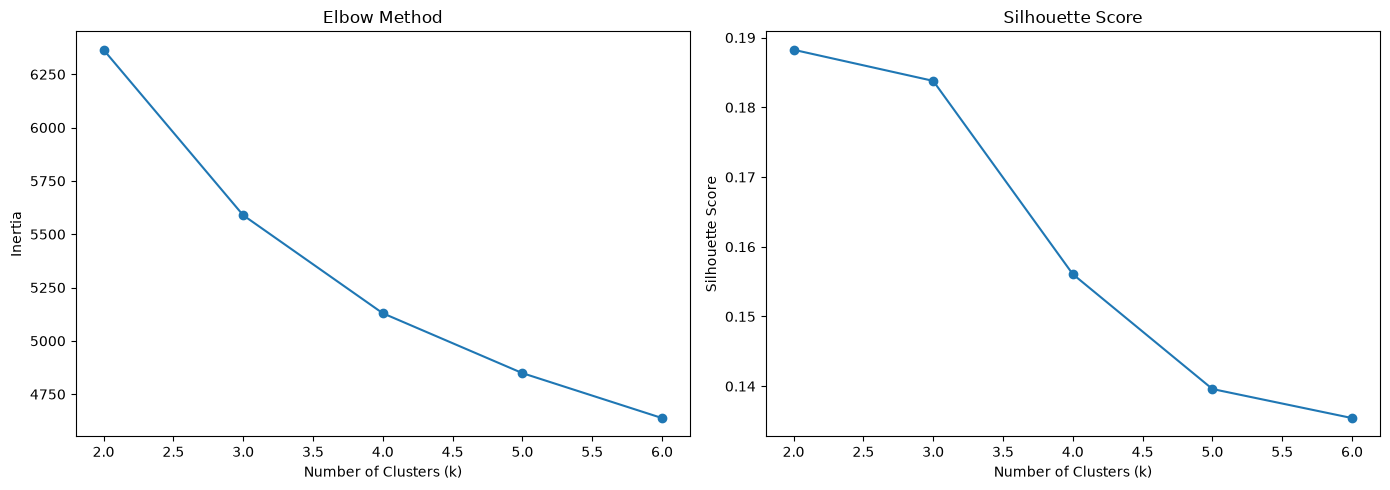

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [5]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=SEED,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(Xtr_scaled)

clustered_data = Xtr.copy()
clustered_data["Cluster"] = cluster_labels

print(clustered_data["Cluster"].value_counts().sort_index())

Cluster
0    183
1    414
2    181
Name: count, dtype: int64


In [6]:
cluster_summary = clustered_data.groupby("Cluster")[FEATURE_COLS].mean()

cluster_summary["Cluster_Size"] = (
    clustered_data["Cluster"].value_counts().sort_index()
)

display(cluster_summary.round(2))

,Age,Weight_kg,Height_m,Max_BPM,Avg_BPM,Resting_BPM,Session_Duration_min,Fat_Percentage,Water_Intake_liters,BMI,Cluster_Size
Cluster,,,,,,,,,,,
0,38.65,103.37,1.79,180.78,144.21,61.83,67.91,25.30,2.97,32.51,183
1,39.03,61.20,1.68,179.01,143.76,62.38,66.60,28.91,2.25,21.87,414
2,38.24,71.98,1.74,181.09,143.10,61.80,101.83,16.20,3.13,23.92,181


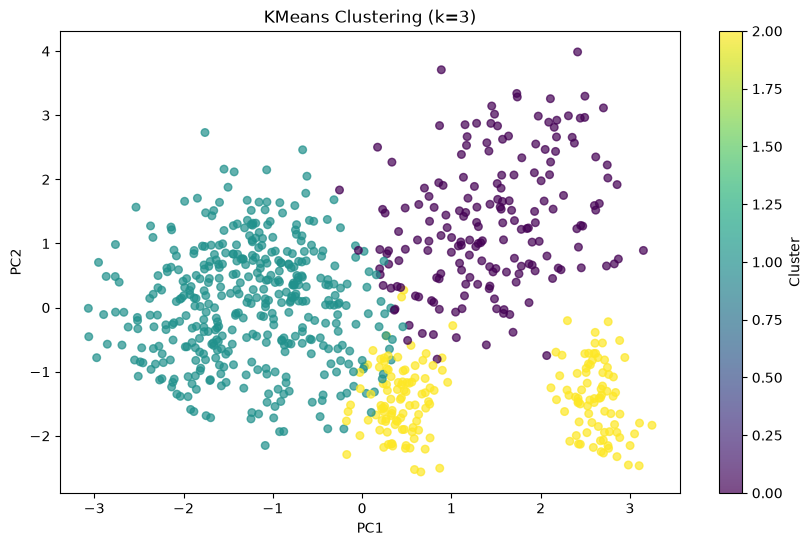

Explained Variance: 0.40923492588240273


In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

Xtr_pca = pca.fit_transform(Xtr_scaled)

plt.figure(figsize=(10, 6))

plt.scatter(
    Xtr_pca[:, 0],
    Xtr_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=30,
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans Clustering (k=3)")
plt.colorbar(label="Cluster")
plt.show()

print("Explained Variance:", pca.explained_variance_ratio_.sum())

In [8]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=2.1,
    min_samples=8
)

dbscan_labels = dbscan.fit_predict(Xtr_scaled)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

n_noise = list(dbscan_labels).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

print("\nCluster distribution:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Number of clusters: 1
Number of noise points: 90

Cluster distribution:
-1     90
 0    688
Name: count, dtype: int64


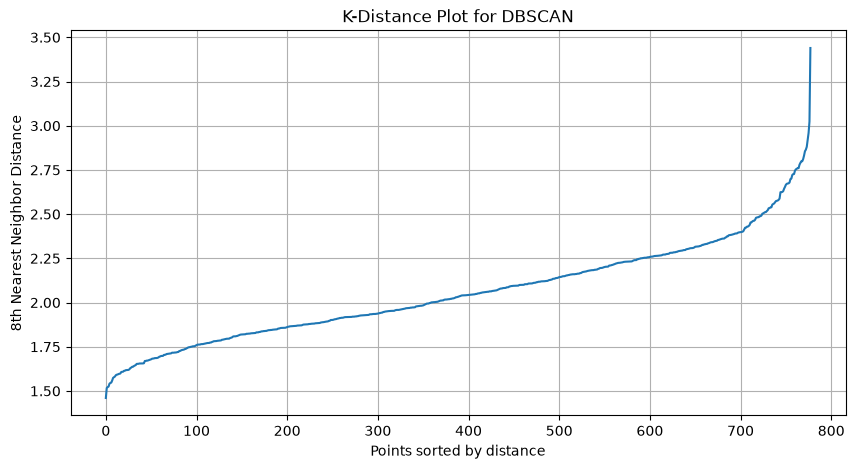

In [9]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=8)
neighbors_fit = neighbors.fit(Xtr_scaled)

distances, indices = neighbors_fit.kneighbors(Xtr_scaled)

distances = np.sort(distances[:, 7])

plt.figure(figsize=(10, 5))
plt.plot(distances)

plt.xlabel("Points sorted by distance")
plt.ylabel("8th Nearest Neighbor Distance")
plt.title("K-Distance Plot for DBSCAN")
plt.grid(True)

plt.show()

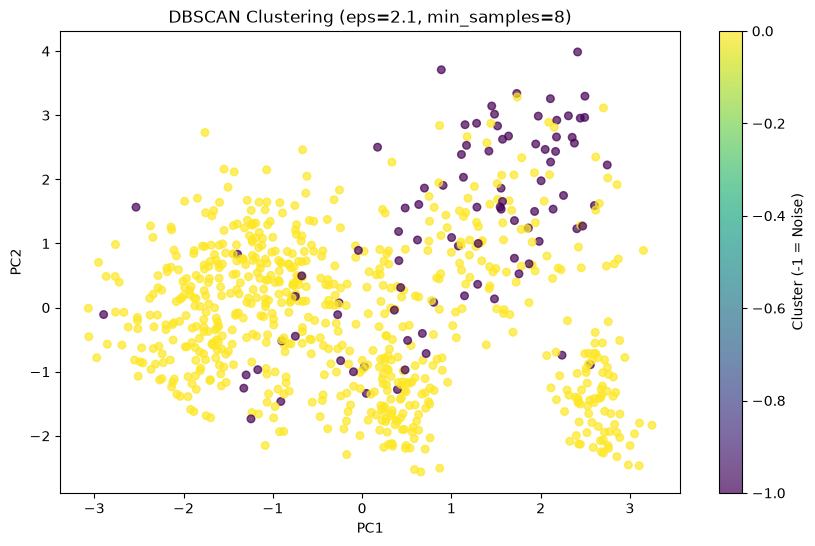

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    Xtr_pca[:, 0],
    Xtr_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=30,
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("DBSCAN Clustering (eps=2.1, min_samples=8)")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.show()

In [11]:
dbscan_tuned = DBSCAN(
    eps=2.4,
    min_samples=8
)

tuned_labels = dbscan_tuned.fit_predict(Xtr_scaled)

print("Clusters:", len(set(tuned_labels) - {-1}))
print("Noise Points:", np.sum(tuned_labels == -1))

print(pd.Series(tuned_labels).value_counts().sort_index())

Clusters: 1
Noise Points: 3
-1      3
 0    775
Name: count, dtype: int64


In [12]:
comparison = pd.DataFrame({
    "Algorithm": ["KMeans", "DBSCAN (eps=2.1)", "DBSCAN (eps=2.4)"],
    "Number_of_Clusters": [
        3,
        n_clusters,
        len(set(tuned_labels) - {-1})
    ],
    "Noise_Points": [
        0,
        n_noise,
        np.sum(tuned_labels == -1)
    ],
    "Total_Points": [len(Xtr)] * 3
})

comparison["Noise_Percentage"] = (
    comparison["Noise_Points"] /
    comparison["Total_Points"] * 100
)

display(comparison.round(2))

,Algorithm,Number_of_Clusters,Noise_Points,Total_Points,Noise_Percentage
0,KMeans,3,0,778,0.00
1,DBSCAN (eps=2.1),1,90,778,11.57
2,DBSCAN (eps=2.4),1,3,778,0.39


# Clustering Results and Conclusion

## KMeans
- Best Silhouette Score: 0.188 at k=2.
- Selected k=3 according to project requirements.
- Cluster sizes: 183, 414, 181.

## DBSCAN
- eps=2.1, min_samples=8:
  - 1 cluster
  - 90 noise points.

- eps=2.4, min_samples=8:
  - 1 cluster
  - 3 noise points.

## Comparison
KMeans identified three distinct groups, while DBSCAN
identified one main cluster and several noise points.

KMeans provided more useful segmentation for this dataset.
DBSCAN was less effective at identifying multiple clusters
using the tested parameters.

## Cluster Interpretation

- Cluster 0: Members with higher average weight and BMI.
- Cluster 1: Members with lower average weight and BMI.
- Cluster 2: Members with longer workout sessions and lower fat percentage.

These groups represent different workout and body composition patterns.